# Laboratorio Práctico: Cumplimiento Técnico del Reglamento de IA de la UE (EU AI Act)
**Objetivo didáctico:** Construir un *pipeline* de Machine Learning auditable de principio a fin que cubra los pilares técnicos exigidos por la Unión Europea para sistemas de **Alto Riesgo** (como la evaluación de solvencia crediticia, Anexo III):
1. **Clasificación de Riesgo** (Artículos 5, 6 y 50).
2. **Gobernanza y Calidad de Datos** (Artículo 10).
3. **Detección y Mitigación de Sesgos** con `Fairlearn` (Artículo 10.2.f).
4. **Transparencia y Explicabilidad** con `SHAP` (Artículos 13 y 86).
5. **Registro Automático (`Logging`) y Supervisión Humana** (Artículos 12 y 14).

In [3]:
!pip list | grep shap

shap                                  0.54.1
shapely                               2.2.0


In [4]:
# Instalación de dependencias (ejecutar una vez en Google Colab o entorno local)
!pip install -q fairlearn

## Paso 0: Clasificador Interactivo de Nivel de Riesgo (EU AI Act)
Antes de entrenar cualquier modelo, la normativa exige clasificar **qué nivel de riesgo** tiene el caso de uso, ya que de ello dependen las obligaciones legales y técnicas.

In [5]:
def clasificar_riesgo_eu_ai_act(caso_uso: dict) -> dict:
    """
    Clasifica un sistema de IA según la pirámide de riesgo del Reglamento (UE) 2024/1689.
    """
    # 1. Riesgo Inaceptable (Artículo 5 - Prohibido desde feb. 2025)
    if (
        caso_uso.get("puntuacion_social_ciudadana")
        or caso_uso.get("manipulacion_subliminal")
        or caso_uso.get("identificacion_biometrica_remota_tiempo_real_publico")
    ):
        return {
            "nivel": "RIESGO INACEPTABLE (PROHIBIDO - Art. 5)",
            "accion": "Despliegue ilegal en la UE. Detener proyecto.",
            "requisitos_tecnicos": ["Ninguno: práctica prohibida."]
        }

    # 2. Alto Riesgo (Artículo 6 + Anexo I y Anexo III)
    sectores_anexo_iii = {
        "credito_solvencia", "seleccion_personal_rrhh", "educacion_admision",
        "salud_dispositivos", "infraestructura_critica", "justicia_policia", "migracion_fronteras"
    }
    if caso_uso.get("sector") in sectores_anexo_iii or caso_uso.get("componente_seguridad_producto_ue"):
        return {
            "nivel": "ALTO RIESGO (Art. 6 / Anexo III)",
            "accion": "Permitido sujeto a evaluación de conformidad y controles estrictos.",
            "requisitos_tecnicos": [
                "Art. 9: Sistema de gestión de riesgos continuo",
                "Art. 10: Gobernanza de datos y auditoría de sesgos (Fairlearn/AIF360)",
                "Art. 11-12: Documentación técnica (Anexo IV) y registro automático de logs",
                "Art. 13: Transparencia y explicabilidad (SHAP/LIME)",
                "Art. 14: Supervisión humana efectiva (Human-in-the-loop)",
                "Art. 15: Precisión, solidez y ciberseguridad"
            ]
        }

    # 3. Riesgo Limitado / Obligaciones de Transparencia (Artículo 50)
    if caso_uso.get("interaccion_chatbot") or caso_uso.get("genera_contenido_sintetico_deepfake"):
        return {
            "nivel": "RIESGO LIMITADO (Obligación de Transparencia - Art. 50)",
            "accion": "Permitido informando al usuario y marcando contenido sintético.",
            "requisitos_tecnicos": [
                "Aviso claro de que se interactúa con una IA",
                "Marcado legible por máquina (C2PA / marcas de agua) para audio, imagen, vídeo o texto"
            ]
        }

    # 4. Riesgo Mínimo o Nulo
    return {
        "nivel": "RIESGO MÍNIMO O NULO",
        "accion": "Uso libre sin obligaciones adicionales (se recomiendan códigos de conducta).",
        "requisitos_tecnicos": ["Buenas prácticas estándar de ingeniería de software."]
    }

# Probamos con nuestro caso de estudio de hoy: Scoring de Crédito
mi_sistema = {
    "nombre": "CreditScore-EU v1.0",
    "sector": "credito_solvencia",
    "puntuacion_social_ciudadana": False,
    "interaccion_chatbot": False
}

resultado = clasificar_riesgo_eu_ai_act(mi_sistema)
print(f"Sistema: {mi_sistema['nombre']}")
print(f"Clasificación: {resultado['nivel']}")
print("Obligaciones técnicas:")
for req in resultado["requisitos_tecnicos"]:
    print(f"  - {req}")

Sistema: CreditScore-EU v1.0
Clasificación: ALTO RIESGO (Art. 6 / Anexo III)
Obligaciones técnicas:
  - Art. 9: Sistema de gestión de riesgos continuo
  - Art. 10: Gobernanza de datos y auditoría de sesgos (Fairlearn/AIF360)
  - Art. 11-12: Documentación técnica (Anexo IV) y registro automático de logs
  - Art. 13: Transparencia y explicabilidad (SHAP/LIME)
  - Art. 14: Supervisión humana efectiva (Human-in-the-loop)
  - Art. 15: Precisión, solidez y ciberseguridad


## Paso 1: Gobernanza y Calidad de Datos (Artículo 10)
Cargamos el archivo `datos_credito_eu_ai_act.csv` (o lo generamos automáticamente si se abre en Google Colab sin subir archivos) y ejecutamos **controles de calidad y trazabilidad**.

In [6]:
import os
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NOMBRE_CSV = "datos_credito_eu_ai_act.csv"

if os.path.exists(NOMBRE_CSV):
    df = pd.read_csv(NOMBRE_CSV)
    print(f"Dataset cargado desde '{NOMBRE_CSV}' ({len(df)} registros).")
else:
    np.random.seed(42)
    n = 600
    edad = np.random.randint(21, 68, size=n)
    genero = np.random.choice(["Femenino", "Masculino"], size=n, p=[0.48, 0.52])
    ingresos_anuales = np.round(np.random.normal(38000, 14000, size=n).clip(14000, 95000), 2)
    deuda_actual = np.round(np.random.uniform(0, 25000, size=n), 2)
    historial_pagos_meses = np.random.randint(0, 120, size=n)
    impagos_previos = np.random.choice([0, 1, 2, 3], size=n, p=[0.65, 0.20, 0.10, 0.05])
    zona_postal_vulnerable = np.random.choice([0, 1], size=n, p=[0.70, 0.30])
    ratio_deuda = deuda_actual / ingresos_anuales
    score = (ingresos_anuales / 10000) * 0.85 - (ratio_deuda * 3.6) + (historial_pagos_meses / 24) * 0.65 - (impagos_previos * 1.45)
    sesgo = np.where(genero == "Femenino", -2.35, 0.0)
    prob = 1 / (1 + np.exp(-(score + sesgo + np.random.normal(0, 0.45, size=n) - 0.5)))
    df = pd.DataFrame({
        "id_solicitante": [f"SOL-{1000+i}" for i in range(n)],
        "edad": edad, "genero": genero, "ingresos_anuales_eur": ingresos_anuales,
        "deuda_actual_eur": deuda_actual, "historial_pagos_meses": historial_pagos_meses,
        "impagos_previos": impagos_previos, "zona_postal_vulnerable": zona_postal_vulnerable,
        "credito_aprobado": (prob >= 0.5).astype(int)
    })
    df.to_csv(NOMBRE_CSV, index=False)
    print(f"Dataset sintético generado y guardado en '{NOMBRE_CSV}'.")

# Huella criptográfica (SHA-256) para trazabilidad de datos (Art. 11 y 12)
hash_datos = hashlib.sha256(pd.util.hash_pandas_object(df).values).hexdigest()[:16]
print(f"Hash de integridad del dataset: {hash_datos}")

# Validaciones de calidad (simulando contratos de Great Expectations)
assert df.isnull().sum().sum() == 0, "Error: Existen valores nulos en el dataset"
assert (df["edad"] >= 18).all(), "Error: Existen solicitantes menores de edad"
assert (df["ingresos_anuales_eur"] > 0).all(), "Error: Ingresos no válidos"
print("Pruebas de calidad de datos superadas correctamente.")
df.head()

Dataset sintético generado y guardado en 'datos_credito_eu_ai_act.csv'.
Hash de integridad del dataset: 789f6c8c55ab76a8
Pruebas de calidad de datos superadas correctamente.


,id_solicitante,edad,genero,ingresos_anuales_eur,deuda_actual_eur,historial_pagos_meses,impagos_previos,zona_postal_vulnerable,credito_aprobado
0,SOL-1000,59,Masculino,20163.03,24268.75,63,0,1,0
1,SOL-1001,49,Masculino,57796.57,23557.88,68,0,1,1
2,SOL-1002,35,Masculino,26019.15,19596.07,7,0,1,0
3,SOL-1003,63,Masculino,76386.30,8871.03,33,0,0,1
4,SOL-1004,28,Femenino,39115.21,10303.27,47,0,0,1


## Paso 2: Entrenamiento del Modelo Base y Auditoría de Sesgos (`Fairlearn`)
Entrenamos un `RandomForestClassifier` y auditamos si el modelo discrimina por **género** (atributo protegido).
* **Paridad Demográfica (Demographic Parity Difference):** Mide la diferencia en la tasa de aprobación entre el grupo más favorecido y el menos favorecido. Un valor cercano a `0` indica equidad; valores altos indican sesgo.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from fairlearn.metrics import MetricFrame, selection_rate, false_negative_rate, demographic_parity_difference

X_raw = df.drop(columns=["id_solicitante", "credito_aprobado"])
y = df["credito_aprobado"]
atributo_sensible = df["genero"]

X = pd.get_dummies(X_raw, drop_first=True)

X_train, X_test, y_train, y_test, sf_train, sf_test = train_test_split(
    X, y, atributo_sensible, test_size=0.25, random_state=42
)

modelo = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

metricas_por_grupo = MetricFrame(
    metrics={
        "Exactitud (Accuracy)": accuracy_score,
        "Tasa de Aprobación": selection_rate,
        "Tasa Falsos Negativos (Rechazo injusto)": false_negative_rate
    },
    y_true=y_test,
    y_pred=y_pred,
    sensitive_features=sf_test
)

print("=== AUDITORÍA DE EQUIDAD POR GRUPO (FAIRLEARN) ===")
print(metricas_por_grupo.by_group.round(3))

dp_diff = demographic_parity_difference(y_test, y_pred, sensitive_features=sf_test)
print(f"\nDiferencia de Paridad Demográfica: {dp_diff:.3f}")
if dp_diff > 0.10:
    print("ALERTA DE CUMPLIMIENTO (Art. 10): Sesgo significativo detectado (> 10%).")

=== AUDITORÍA DE EQUIDAD POR GRUPO (FAIRLEARN) ===
           Exactitud (Accuracy)  Tasa de Aprobación  \
genero                                                
Femenino                  0.885               0.590   
Masculino                 0.888               0.933   

           Tasa Falsos Negativos (Rechazo injusto)  
genero                                              
Femenino                                     0.061  
Masculino                                    0.000  

Diferencia de Paridad Demográfica: 0.342
ALERTA DE CUMPLIMIENTO (Art. 10): Sesgo significativo detectado (> 10%).


## Paso 3: Explicabilidad Global y Local con `SHAP` (Artículo 13)
El Reglamento de la UE exige que los sistemas de alto riesgo sean suficientemente transparentes para que los supervisores humanos interpreten sus resultados, y reconoce el derecho de las personas afectadas a recibir una **explicación clara** de las decisiones individuales (Artículo 86).
* **Explicabilidad Global:** ¿Qué variables pesan más en todo el modelo? (Aquí los estudiantes verán cómo `genero_Masculino` aparece como un factor relevante debido al sesgo histórico).
* **Explicabilidad Local:** ¿Por qué exactamente se le denegó el crédito al solicitante `X`?

Gráfico 1: Impacto global de cada variable en la aprobación del crédito


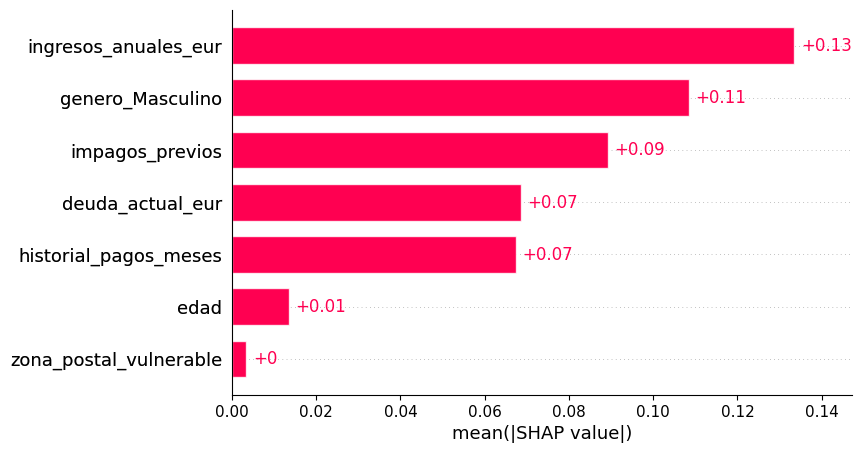


Gráfico 2: Explicación individual (Waterfall) para el caso de prueba #0
Datos del solicitante: {'edad': 59, 'ingresos_anuales_eur': 34724.13, 'deuda_actual_eur': 16084.13, 'historial_pagos_meses': 7, 'impagos_previos': 0, 'zona_postal_vulnerable': 1, 'genero_Masculino': False}


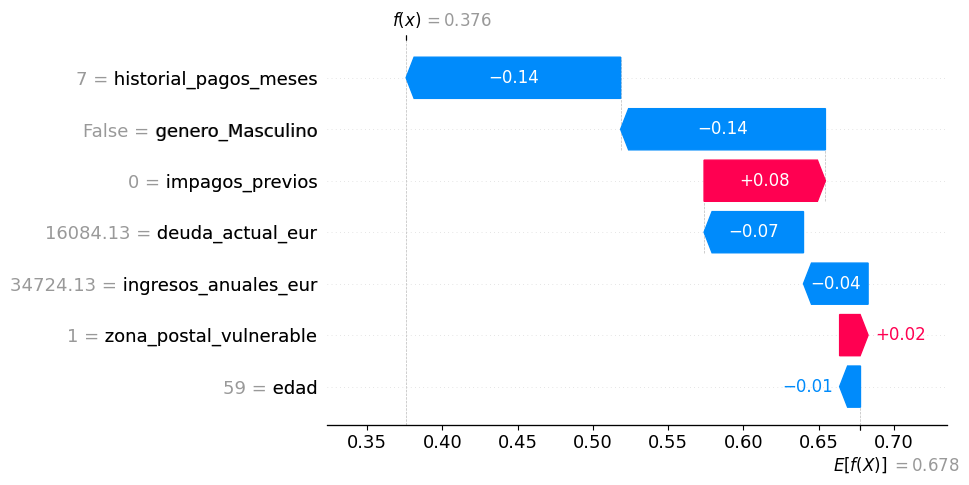

In [8]:
import shap

explainer = shap.TreeExplainer(modelo)
shap_values = explainer(X_test)

# Para clasificación binaria en scikit-learn, seleccionamos la clase 1 (Crédito Aprobado)
shap_clase_1 = shap_values[:, :, 1]

# 3.1 Explicabilidad Global
print("Gráfico 1: Impacto global de cada variable en la aprobación del crédito")
shap.plots.bar(shap_clase_1, max_display=8)

# 3.2 Explicabilidad Local (Waterfall plot para un solicitante rechazado)
indices_rechazados = np.where(y_pred == 0)[0]
idx_ejemplo = indices_rechazados[0]

print(f"\nGráfico 2: Explicación individual (Waterfall) para el caso de prueba #{idx_ejemplo}")
print("Datos del solicitante:", X_test.iloc[idx_ejemplo].to_dict())
shap.plots.waterfall(shap_clase_1[idx_ejemplo])

## Paso 4: Mitigación del Sesgo (Post-procesamiento con `Fairlearn`)
Una vez que **SHAP** y **Fairlearn** confirman que el modelo penaliza injustamente a un grupo por datos históricos sesgados, aplicamos `ThresholdOptimizer` de Fairlearn para igualar las oportunidades de aprobación sin destruir la precisión del negocio.

In [9]:
from fairlearn.postprocessing import ThresholdOptimizer

mitigador = ThresholdOptimizer(
    estimator=modelo,
    constraints="equalized_odds",
    predict_method="predict_proba",
    prefit=True
)

mitigador.fit(X_train, y_train, sensitive_features=sf_train)
y_pred_mitigado = mitigador.predict(X_test, sensitive_features=sf_test)

metricas_mitigadas = MetricFrame(
    metrics={
        "Exactitud (Accuracy)": accuracy_score,
        "Tasa de Aprobación": selection_rate,
        "Tasa Falsos Negativos": false_negative_rate
    },
    y_true=y_test,
    y_pred=y_pred_mitigado,
    sensitive_features=sf_test
)

print("=== RESULTADOS TRAS MITIGACIÓN DE SESGO ===")
print(metricas_mitigadas.by_group.round(3))
dp_diff_post = demographic_parity_difference(y_test, y_pred_mitigado, sensitive_features=sf_test)
print(f"\nNueva Diferencia de Paridad Demográfica: {dp_diff_post:.3f} (Antes: {dp_diff:.3f})")

=== RESULTADOS TRAS MITIGACIÓN DE SESGO ===
           Exactitud (Accuracy)  Tasa de Aprobación  Tasa Falsos Negativos
genero                                                                    
Femenino                  0.885               0.590                  0.061
Masculino                 0.888               0.843                  0.055

Nueva Diferencia de Paridad Demográfica: 0.253 (Antes: 0.342)


## Paso 5: Registro Automático (`Logging`) y Supervisión Humana (Artículos 12 y 14)
Para superar una auditoría de la UE, cada predicción en producción debe quedar registrada con trazabilidad y escalar automáticamente a un **revisor humano** cuando la confianza del modelo sea baja o la decisión sea desfavorable.

In [11]:
import datetime
import json

def predecir_con_gobernanza(indice_test: int) -> dict:
    fila = X_test.iloc[[indice_test]]
    prob_aprobacion = float(modelo.predict_proba(fila)[0][1])
    decision_final = int(y_pred_mitigado[indice_test])

    # Top 3 factores SHAP que explican esta decisión concreta
    valores_ind = shap_clase_1[indice_test].values
    nombres_vars = X_test.columns
    top_idx = np.argsort(np.abs(valores_ind))[::-1][:3]
    factores = {nombres_vars[i]: round(float(valores_ind[i]), 3) for i in top_idx}

    # Regla de Supervisión Humana (Art. 14): escalar si hay incertidumbre o rechazo
    requiere_revision_humana = (0.40 <= prob_aprobacion <= 0.60) or (decision_final == 0)

    registro_auditoria = {
        "timestamp_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
        "modelo_version": "CreditScore-EU-v1.0-mitigated",
        "dataset_sha256": hash_datos,
        "decision": "APROBADO" if decision_final == 1 else "DENEGADO",
        "probabilidad_base": round(prob_aprobacion, 3),
        "principales_factores_shap": factores,
        "escalado_supervisor_humano": requiere_revision_humana
    }
    return registro_auditoria

# Ejemplo de log generado para un solicitante
log_ejemplo = predecir_con_gobernanza(idx_ejemplo)
print(json.dumps(log_ejemplo, indent=2, ensure_ascii=False))

{
  "timestamp_utc": "2026-11-25T15:19:45.521536+00:00",
  "modelo_version": "CreditScore-EU-v1.0-mitigated",
  "dataset_sha256": "789f6c8c55ab76a8",
  "decision": "DENEGADO",
  "probabilidad_base": 0.376,
  "principales_factores_shap": {
    "historial_pagos_meses": -0.143,
    "genero_Masculino": -0.136,
    "impagos_previos": 0.081
  },
  "escalado_supervisor_humano": true
}
